# Channels, promotions and products

Channel results use first-touch channel: how a user was first acquired, not the source of each visit. Promotion results are observational comparisons, not effects of the promotions.

In [1]:
import sys
sys.path.insert(0, "scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analysis as a

pd.set_option("display.float_format", "{:,.4f}".format)
a.chart_style()
con = a.connect()
q = lambda sql: con.sql(sql).df()

## Channel quality

New users first seen 12–30 November, each followed for exactly 56 days of order tracking, so every channel gets the same window.

In [2]:
ch = q("SELECT * FROM channel_quality")
for r in ch.itertuples():
    print(f"{r.channel} brings {r.share_of_users:.1%} of new users but {r.share_of_revenue:.1%} of their 56-day revenue")
ch

Organic Search brings 37.1% of new users but 32.0% of their 56-day revenue
Direct brings 23.8% of new users but 22.4% of their 56-day revenue
Unknown brings 19.0% of new users but 24.4% of their 56-day revenue
Referral brings 15.1% of new users but 18.5% of their 56-day revenue
Paid Search brings 4.9% of new users but 2.7% of their 56-day revenue


,channel,users,buyers_56d,revenue_56d,share_of_users,share_of_revenue,buyer_rate_56d,revenue_per_user_56d
0,Organic Search,17516,267,"25,052.0000",0.3713,0.3198,0.0152,1.4302
1,Direct,11249,192,"17,527.0000",0.2385,0.2238,0.0171,1.5581
2,Unknown,8948,208,"19,079.0000",0.1897,0.2436,0.0232,2.1322
3,Referral,7133,170,"14,518.0000",0.1512,0.1853,0.0238,2.0353
4,Paid Search,2326,29,"2,154.0000",0.0493,0.0275,0.0125,0.9261


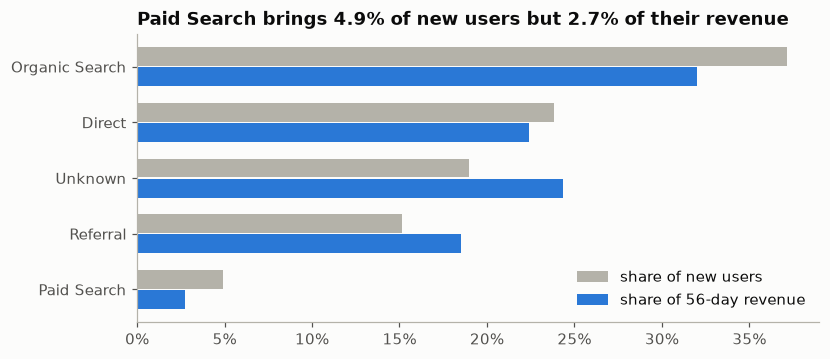

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(ch))[::-1]
ax.barh(y + 0.18, ch.share_of_users, height=0.34, color=a.GRAY, label="share of new users")
ax.barh(y - 0.18, ch.share_of_revenue, height=0.34, color=a.BLUE, label="share of 56-day revenue")
ax.set_yticks(y, ch.channel)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, loc="lower right")
ps = ch.set_index("channel").loc["Paid Search"]
ax.set_title(f"Paid Search brings {ps.share_of_users:.1%} of new users but {ps.share_of_revenue:.1%} of their revenue")
fig.savefig("charts/channel_quality.png")

The obfuscated "Unknown" channel is kept as its own group. It holds about a fifth of new users and a quarter of their revenue, so dropping it would distort every other channel's share.

Referral and Unknown users are the most valuable per head. Paid Search users are the least.

## Promotions

Sessions that clicked a promotion against those that did not. The adjusted gap reweights both groups to the overall mix of device × new/returning sessions, so it removes differences in who clicks.

In [4]:
promo = q("SELECT * FROM promo_effect")
promo.T

,0
promo_sessions,"5,768.0000"
other_sessions,"242,901.0000"
promo_raw_conversion,0.0357
other_raw_conversion,0.0123
raw_gap,0.0234
promo_adjusted_conversion,0.0375
other_adjusted_conversion,0.0123
adjusted_gap,0.0252


In [5]:
q("""SELECT device_category, is_new_session, has_select_promotion, COUNT(*) AS sessions, AVG(has_order::INT) AS conversion
     FROM fact_sessions WHERE in_funnel_window GROUP BY ALL ORDER BY ALL""")

,device_category,is_new_session,has_select_promotion,sessions,conversion
0,desktop,False,False,35752,0.0307
1,desktop,False,True,738,0.0718
2,desktop,True,False,105190,0.0059
3,desktop,True,True,2563,0.0199
4,mobile,False,False,24739,0.0301
5,mobile,False,True,533,0.0919
6,mobile,True,False,71781,0.0064
7,mobile,True,True,1823,0.0263
8,tablet,False,False,1357,0.0324
9,tablet,False,True,18,0.1111


Promotion clickers convert about three times as often. Adjusting for device and new/returning mix leaves the gap slightly larger, so that mix does not explain it.

Clicking a promotion is still self-selected intent, so this does not show that promotions cause orders. A holdout test would.

## Category funnel

Sessions that viewed, carted and ordered each category. Purchase and checkout events use a different category taxonomy and `item_id` format from view events, so each item takes the category its name most often carries on `view_item`. "Unknown" holds purchased items whose name never appears on a view event, which is why its bars grow.

In [6]:
cat = q("SELECT * FROM category_funnel")
con.close()
cat

,category,view_sessions,cart_sessions,order_sessions,view_to_cart,cart_to_order,view_to_order
0,Apparel,27930,9737,1957,0.3486,0.2010,0.0701
1,Brand collections,17235,6186,550,0.3589,0.0889,0.0319
2,Other,15670,5075,956,0.3239,0.1884,0.0610
3,Sale,13814,5294,485,0.3832,0.0916,0.0351
4,Lifestyle,11383,3571,931,0.3137,0.2607,0.0818
5,Bags,7928,2165,343,0.2731,0.1584,0.0433
6,Stationery,5867,2367,635,0.4034,0.2683,0.1082
7,Drinkware,5679,2033,334,0.3580,0.1643,0.0588
8,Unknown,12,132,287,11.0000,2.1742,23.9167


Stationery and Lifestyle turn views into orders best. Brand collections and Sale convert carts into orders at half the Apparel rate: the products get carted but not bought.

All rates are session-level and observational. The 485 Sale order sessions also count discounted items bought in sessions that viewed full-price ones.